# Daily challenge — Data science salaries

Octopus Week 2 · Day 2

[Assignment](https://octopus.developers.institute/courses/collection/254/course/812/section/1694/chapter/3308)

Run cells in order. Source datasets are in `../data`; see the root README for setup and provenance.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'analysis_utils.py').exists())
sys.path.insert(0, str(ROOT))
sns.set_theme(style='whitegrid')
def load(kind, filename=None, **kwargs):
    files = list((ROOT / 'data' / kind).rglob(filename or '*.csv'))
    if len(files) != 1:
        raise ValueError(f'Select an unambiguous data file: {files}')
    return pd.read_csv(files[0], **kwargs)
def savefig(name):
    target = ROOT / 'figures'
    target.mkdir(exist_ok=True)
    plt.tight_layout()
    plt.savefig(target / (name + '.png'), dpi=140, bbox_inches='tight')
    plt.show()


## Import, explore and clean
Use the exact salary dataset provided by Octopus. Remove a CSV index column, but retain repeated job listings because no unique listing identifier establishes that they are errors. Check currencies before aggregating monetary values. Never compare mixed local currencies as if they were the same unit.

In [2]:
salary=load('salaries').drop(columns=['Unnamed: 0'],errors='ignore')
display(salary.head()); display(salary.describe(include='all'))
print('Missing:',salary.isna().sum().to_dict())
print('Repeated attribute rows:',salary.duplicated().sum())
print('Currencies:',salary['salary_currency'].value_counts().to_dict())
assert salary['salary'].notna().all() and (salary['salary']>=0).all()

,job_title,job_type,experience_level,location,salary_currency,salary
0,Data scientist,Full Time,Senior,New York City,USD,149000
1,Data scientist,Full Time,Senior,Boston,USD,120000
2,Data scientist,Full Time,Senior,London,USD,68000
3,Data scientist,Full Time,Senior,Boston,USD,120000
4,Data scientist,Full Time,Senior,New York City,USD,149000


,job_title,job_type,experience_level,location,salary_currency,salary
count,1171,1171,1171,1171,1171,1171.000000
unique,5,2,4,320,3,NaN
top,Data scientist,Full Time,Senior,London,USD,NaN
freq,394,1136,727,75,1157,NaN
mean,NaN,NaN,NaN,NaN,NaN,64836.037575
std,NaN,NaN,NaN,NaN,NaN,32551.767046
min,NaN,NaN,NaN,NaN,NaN,30000.000000
25%,NaN,NaN,NaN,NaN,NaN,45000.000000
50%,NaN,NaN,NaN,NaN,NaN,63000.000000
75%,NaN,NaN,NaN,NaN,NaN,68000.000000


Missing: {'job_title': 0, 'job_type': 0, 'experience_level': 0, 'location': 0, 'salary_currency': 0, 'salary': 0}
Repeated attribute rows: 345
Currencies: {'USD': 1157, 'EUR': 9, 'GBP': 5}


## Min-max salary normalization

In [3]:
from analysis_utils import normalize_salary
salary['salary_normalized']=normalize_salary(salary['salary'])
display(salary[['salary','salary_normalized']].head())
assert np.isclose(salary['salary_normalized'].min(),0) and np.isclose(salary['salary_normalized'].max(),1)

,salary,salary_normalized
0,149000,0.601010
1,120000,0.454545
2,68000,0.191919
3,120000,0.454545
4,149000,0.601010


## Dimensionality reduction with PCA
Drop the redundant normalized salary from PCA input, encode job/experience/location/currency/type categorically, then standardize the encoded feature matrix before projecting onto two components. PCA uses USD listings only so the numeric salary feature has a consistent unit. This is exploratory PCA; a model predicting salary must exclude salary itself and fit preprocessing on training data only. Coordinates of one-hot PCA are not causal factors.

Original dimensions: 330 ; reduced dimensions: 2
Explained variance: [0.00862937 0.00743286] ; total: 0.016062231334022688


,PC1,PC2
0,2.157637,0.755711
1,2.044830,0.471707
2,0.911148,0.010920
3,2.044830,0.471707
4,2.157637,0.755711


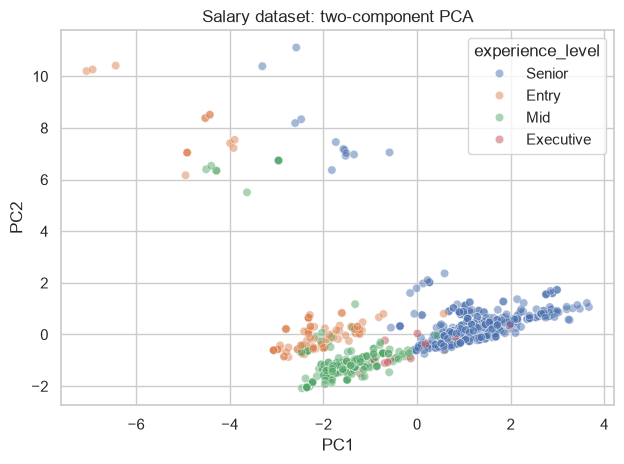

In [4]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
pca_salary=salary[salary['salary_currency']=='USD'].copy()
x=pd.get_dummies(pca_salary.drop(columns=['salary_normalized','salary_currency']),dtype=float)
scaled=StandardScaler().fit_transform(x)
pca=PCA(n_components=2,svd_solver='full')
coords=pca.fit_transform(scaled)
print('Original dimensions:',x.shape[1],'; reduced dimensions:',coords.shape[1])
print('Explained variance:',pca.explained_variance_ratio_, '; total:',pca.explained_variance_ratio_.sum())
display(pd.DataFrame(coords,columns=['PC1','PC2']).head())
sns.scatterplot(x=coords[:,0],y=coords[:,1],hue=pca_salary['experience_level'],alpha=.5)
plt.title('Salary dataset: two-component PCA');plt.xlabel('PC1');plt.ylabel('PC2')
savefig('day2_salary_pca')

## Experience-level aggregation
Report mean, median and count by experience and currency, preserving monetary units. Counts help distinguish well-represented roles from sparse categories. The unadjusted differences may reflect location and job-title composition.

count      mean   median
salary_currency experience_level                          
EUR             Mid                   2  54000.00  54000.0
                Senior                7  45285.71  36000.0
GBP             Mid                   4  48750.00  45000.0
                Senior                1  57000.00  57000.0
USD             Entry               126  36111.11  30000.0
                Executive            13  76076.92  46000.0
                Mid                 299  51812.71  51000.0
                Senior              719  75403.34  68000.0

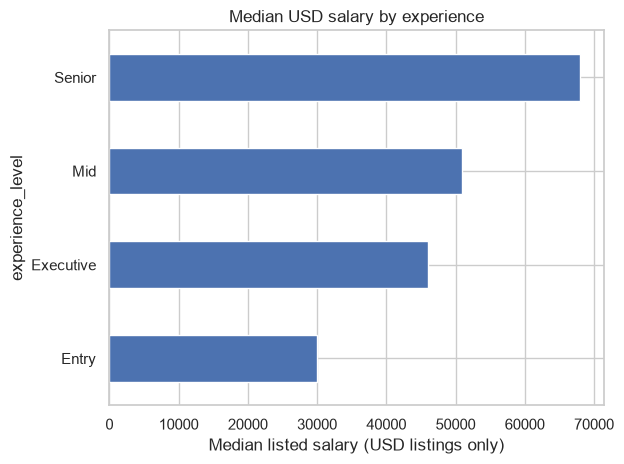

Highest median USD group: Senior (68,000)
Lowest median USD group: Entry (30,000)
PCA keeps 1.6% of standardized variance: two axes lose information.


In [5]:
summary=salary.groupby(['salary_currency','experience_level'])['salary'].agg(['count','mean','median']).round(2)
display(summary)
summary.to_csv(ROOT/'day2'/'salary_summary.csv')
g=salary[salary['salary_currency']=='USD'].groupby('experience_level')['salary'].median().sort_values()
g.plot.barh();plt.xlabel('Median listed salary (USD listings only)');plt.title('Median USD salary by experience')
savefig('day2_salary_by_experience')
print('Highest median USD group:',g.index[-1],f'({g.iloc[-1]:,.0f})')
print('Lowest median USD group:',g.index[0],f'({g.iloc[0]:,.0f})')
print('PCA keeps',f'{pca.explained_variance_ratio_.sum():.1%}','of standardized variance: two axes lose information.')

## Interpretation
Normalization places observed salaries on a common numeric range but does not remove location, role or seniority effects. PCA demonstrates compression rather than a salary prediction. Use the displayed currency-aware table to compare experience groups; this convenience sample of listings is not an estimate of all workers' pay. Validate missing compensation, selection bias and repeated listings before recruitment policy decisions.